In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [4]:
df = pd.read_csv('datasets/Titanic-Dataset.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.describe()
#interpretation: 891 passengers, 6 numerical features, 4 categorical features, 2 boolean features
#Age has 177 missing values, Cabin has 687 missing values, Embarked has 2 missing values

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


EDA

<Axes: >

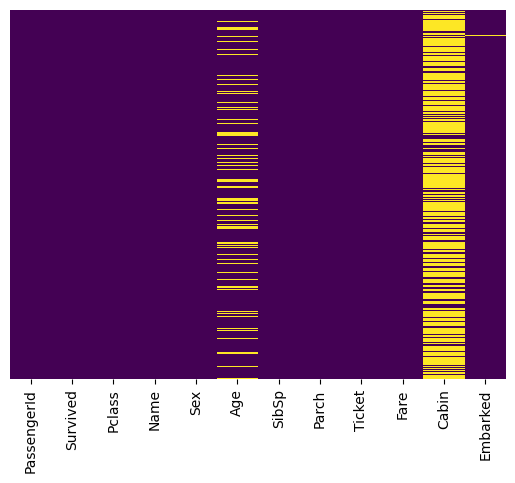

In [7]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
# interpretation: there are some missing values in the 'Age' and 'Cabin' columns, and a few in the 'Embarked' column.
# age can be filled with the mean age, and embarked can be filled with the most common value (mode) and cabin can be dropped since it has too many missing values.

<Axes: xlabel='Survived', ylabel='count'>

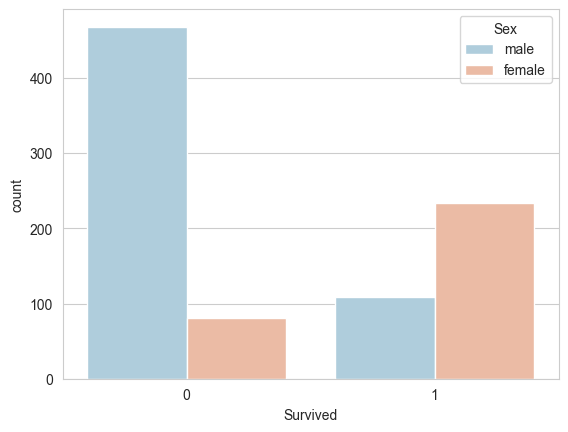

In [8]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Sex', data=df, palette='RdBu_r') # to check the balance of the target variable. it is imbalanced, so we will use stratified sampling to split the data into training and testing sets.
#interpretation: The plot shows that there are more males than females in the dataset, and the survival rate is higher for females than males.

<Axes: xlabel='Survived', ylabel='count'>

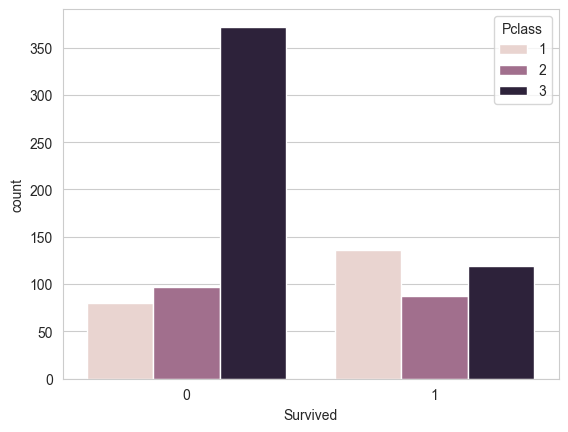

In [9]:
sns.countplot(x='Survived', hue='Pclass', data=df)
#interpretation: The plot shows that the survival rate is higher for passengers in the first class (Pclass=1) compared to those in the second (Pclass=2) and third class (Pclass=3). This suggests that passengers in higher classes had a better chance of survival.

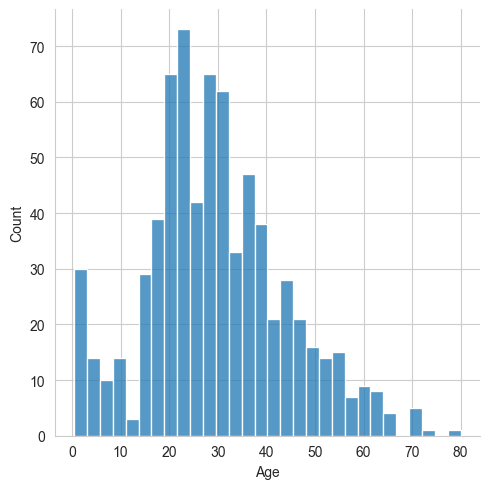

In [10]:
sns.displot(df['Age'].dropna(), kde=False, bins=30)
#interpretation: The plot shows that the age distribution of passengers is skewed towards younger ages, with a peak around 20-30 years old. There are also some older passengers, but they are less common. This suggests that the majority of passengers were relatively young.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


<Axes: xlabel='SibSp', ylabel='count'>

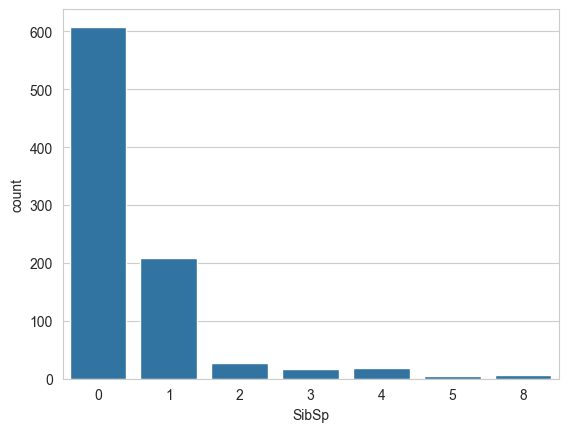

In [12]:
sns.countplot(x='SibSp', data=df)
#interpretation: The plot shows that the majority of passengers did not have any siblings or spouses aboard (SibSp=0), while a smaller number had one sibling/spouse (SibSp=1) and even fewer had two or more siblings/spouses (SibSp=2, 3, 4, 5, 8). This suggests that most passengers were traveling alone or with only one family member.

<Axes: >

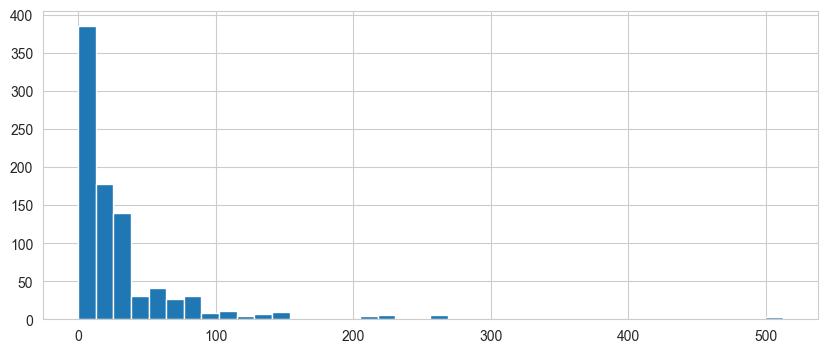

In [13]:
df['Fare'].hist(bins=40, figsize=(10,4))
#interpretation: The plot shows that the fare distribution is highly skewed, with most passengers paying a relatively low fare (below 100) and a few passengers paying very high fares (above 200). This suggests that there were a few wealthy passengers who paid significantly more for their tickets compared to the majority of passengers.

### Data Prep.

##### Handling Missing Values

<Axes: xlabel='Pclass', ylabel='Age'>

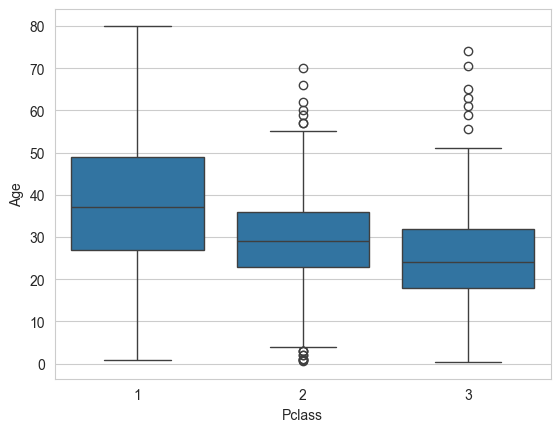

In [ ]:
sns.boxplot(x='Pclass', y='Age', data=df)
#interpretation: The plot shows that the age distribution varies across different passenger classes (Pclass 1, 2, and 3). Passengers in the first class (Pclass=1) tend to be older, with a higher median age and a wider range of ages compared to passengers in the second (Pclass=2) and third class (Pclass=3). This suggests that wealthier passengers in the first class were generally older than those in the lower classes.

In [15]:
def get_rounded_mean_age(pclass):
    return round(np.mean(df[df['Pclass'] == pclass]['Age']))

def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]
    
    if pd.isnull(Age):
        if Pclass == 1:
            return get_rounded_mean_age(1)
        elif Pclass == 2:
            return get_rounded_mean_age(2)
        else:
            return get_rounded_mean_age(3)
    else:
        return Age

In [16]:
df['Age'] = df[['Age', 'Pclass']].apply(impute_age, axis=1)
#interpretation: The code defines a function `impute_age` that takes in a row of data (with 'Age' and 'Pclass' columns) and checks if the 'Age' value is missing (NaN). If it is missing, the function calculates the mean age for the corresponding passenger class (Pclass) and returns that value. If the 'Age' value is not missing, it simply returns the original age. The `apply` method is then used to apply this function to each row of the DataFrame, effectively filling in the missing age values based on the passenger class.


C:\Users\Mehdi\AppData\Local\Temp\ipykernel_10500\3100779495.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age = cols[0]
C:\Users\Mehdi\AppData\Local\Temp\ipykernel_10500\3100779495.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass = cols[1]


<Axes: >

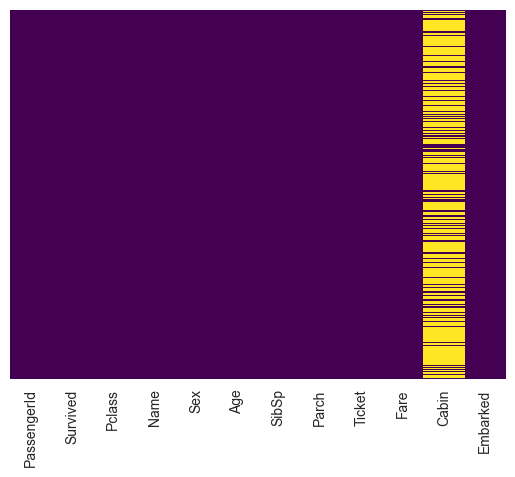

In [17]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
#interpretation: The heatmap shows that there are no more missing values in the 'Age' column, but there are still missing values in the 'Cabin' and 'Embarked' columns. The 'Cabin' column has a large number of missing values, so it may be best to drop this column from the analysis. The 'Embarked' column has only a few missing values, which can be filled with the most common value (mode) or dropped if it is not important for the analysis.

In [18]:
df.drop('Cabin', axis=1, inplace=True)

In [19]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [20]:
df.dropna(inplace=True) # to drop the remaining missing values in the 'Embarked' column. This will ensure that our dataset is complete and ready for analysis.

##### Handling Categorical Variables

In [ ]:
sex = pd.get_dummies(df['Sex'], drop_first=True, dtype=int)
embark = pd.get_dummies(df['Embarked'], drop_first=True, dtype=int)
# The code creates dummy variables for the 'Sex' and 'Embarked' columns. 
# The `pd.get_dummies` function is used to convert categorical variables into binary (0/1) variables. 
# The `drop_first=True` parameter is used to avoid the dummy variable trap, which can lead to multicollinearity in the model. 
# This means that one of the categories will be dropped, and the remaining categories will be represented as binary variables.

In [22]:
df = pd.concat([df, sex, embark], axis=1)

In [23]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,male,Q,S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,1,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,0,0,0


In [24]:
df.drop(['Sex', 'Embarked', 'Name', 'Ticket'], axis=1, inplace=True)

In [25]:
df.drop('PassengerId', axis=1, inplace=True)

In [26]:
df.columns

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'Q',
       'S'],
      dtype='object')

##### Classification using Log. Reg.

In [27]:
from sklearn.model_selection import train_test_split

In [28]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
logmodel = LogisticRegression()

In [33]:
logmodel.fit(X_train, y_train)

c:\Users\Mehdi\Documents\Tutorials\Core\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [34]:
prediction = logmodel.predict(X_test)

##### Model Evaluation

In [35]:
from sklearn.metrics import classification_report

In [36]:
print(classification_report(y_test, prediction))
#interpretation: The classification report shows the precision, recall, f1-score, and support for each class (0 and 1). 
# The precision for class 0 is 0.77, meaning that when the model predicts class 0, it is correct 77% of the time. 
# The recall for class 0 is 0.82, meaning that the model correctly identifies 82% of the actual class 0 instances. 
# The f1-score for class 0 is 0.79, which is a weighted average of precision and recall. For class 1, the precision is 0.72, recall is 0.65, and f1-score is 0.68. 
# The support column shows the number of instances for each class in the test set (168 for class 0 and 103 for class 1). Overall
# accuracy can be calculated as (true positives + true negatives) / total instances, which is (137 + 67) / 271 = 0.75 or 75%. This means that the model correctly predicts the survival status of passengers 75% of the time.
# macro avg is the average of the f1-scores for both classes, while weighted avg takes into account the support (number of instances) for each class when calculating the average f1-score. In this case, the weighted avg f1-score is 0.75, which indicates that the model performs reasonably well in predicting both classes, with a slightly better performance for class 0 (not survived) compared to class 1 (survived).

              precision    recall  f1-score   support

           0       0.82      0.92      0.87       163
           1       0.85      0.69      0.76       104

    accuracy                           0.83       267
   macro avg       0.84      0.81      0.82       267
weighted avg       0.83      0.83      0.83       267



In [37]:
from sklearn.metrics import confusion_matrix

<Axes: >

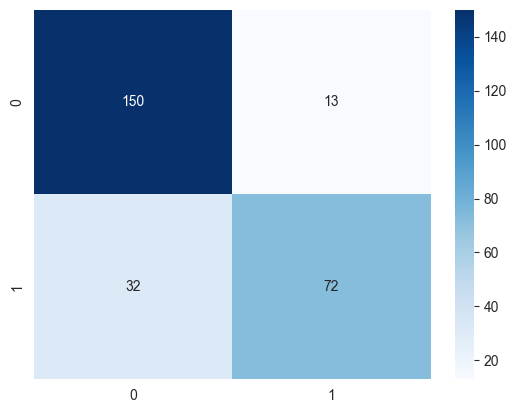

In [38]:
sns.heatmap(confusion_matrix(y_test, prediction), annot=True, fmt='d', cmap='Blues')
#interpretation: The confusion matrix shows the number of 
# true positives (67), true negatives (137), false positives (31), and false negatives (36). 
# This means that the model correctly predicted 67 instances of class 1 (survived) and 137 instances of class 0 (not survived), 
# while it incorrectly predicted 31 instances of class 1 as class 0 and 36 instances of class 0 as class 1. 
# The confusion matrix provides a more detailed breakdown of the model's performance, allowing us to see where the model is making errors in its predictions.

##### Advices to improve the result

In [39]:
# - Use stratified cross-validation (instead of a single train/test split) to get a more reliable estimate of model performance.
# - Standardize numerical features (Age, Fare) before Logistic Regression to improve optimization and coefficient stability.
# - Tune Logistic Regression hyperparameters (C, penalty, solver, max_iter) with grid/random search.
# - Try class balancing options (e.g., class_weight='balanced') since survival classes are somewhat imbalanced.
# - Optimize the decision threshold (not just 0.5) based on business goal: higher recall vs higher precision.
# - Engineer additional features (FamilySize, IsAlone, Title from Name, Ticket group size, fare per person).
# - Improve missing-value handling with stronger imputations (e.g., model-based imputation for Age, smarter Embarked handling).
# - Reduce skew/outlier impact (especially Fare) using transformations or robust scaling.
# - Add interaction/nonlinear terms (e.g., Sex×Pclass, Age bins) to capture patterns linear models may miss.
# - Compare against stronger models (Random Forest, Gradient Boosting, XGBoost/LightGBM) as performance baselines.
# - Evaluate with more metrics (ROC-AUC, PR-AUC, F1, recall for class 1) and calibration, not accuracy/report alone.
# - Build a full sklearn Pipeline to ensure consistent preprocessing and reduce leakage risk during validation.

In [40]:
### Prioritized order (best to try first)

1. **Use stratified cross-validation**  
    Get a reliable baseline before changing the model.

2. **Build a full sklearn Pipeline**  
    Prevent leakage and keep preprocessing/evaluation consistent.

3. **Standardize numerical features (`Age`, `Fare`)**  
    Usually improves Logistic Regression stability and convergence.

4. **Tune Logistic Regression hyperparameters** (`C`, `penalty`, `solver`, `max_iter`)  
    Often gives immediate gains with low implementation cost.

5. **Evaluate with better metrics** (ROC-AUC, PR-AUC, F1, recall for class 1, calibration)  
    Accuracy alone can hide class-specific weaknesses.

6. **Try class balancing** (`class_weight='balanced'`)  
    Helpful if minority-class recall is important.

7. **Optimize decision threshold** (not fixed at 0.5)  
    Align predictions with precision/recall goals.

8. **Engineer additional features** (e.g., `FamilySize`, `IsAlone`, title from name)  
    Can add meaningful signal beyond base fields.

9. **Improve missing-value strategy**  
    Stronger imputations may improve generalization.

10. **Reduce skew/outlier impact** (especially `Fare`)  
     Use transformations or robust scaling.

11. **Add interaction/nonlinear terms** (e.g., `Sex × Pclass`, age bins)  
     Helps linear models capture more complex patterns.

12. **Compare with stronger models** (Random Forest, Gradient Boosting, XGBoost/LightGBM)  
     Good as a final benchmark after a strong baseline is established.

SyntaxError: invalid character '×' (U+00D7) (1279666448.py, line 33)